# Project 2 — Transfer Learning with Pretrained Keras Applications
**MSDS 565 | TeamKAI — KeiTonia, Ashley, India**  
**Notebook 3 of 4 | CRISP-DM: Modeling and Evaluation**

**Central question:** how much does model size actually buy you on a small custom dataset?

**Approach:** we use several pretrained Keras applications of different sizes **exactly as downloaded** (their weights never change). Each one turns an image into a list of numbers called an *embedding*. The only thing we train is a very small Keras model, a **linear probe** (one `Dense` layer), that maps an embedding to one of our five cloud classes. We do **not** build or train a CNN from scratch.

**In simple terms**
- A pretrained application is like a very experienced photo reader. It already knows how to describe pictures as numbers.
- The probe is a tiny "translator" that learns to turn those numbers into "cumulus", "stratus", and so on.
- Because every probe is identical, any difference in accuracy comes from the application underneath it, not from the probe.

### What this notebook expects from Notebook 2
The four arrays and the label map that Notebook 2 saved in its `OUT_DIR` folder (outside the repo):

| File | What it holds |
|---|---|
| `x_train.npy`, `x_test.npy` | images as raw 0-255 `uint8` arrays, already resized to 224 x 224 x 3 |
| `y_train.npy`, `y_test.npy` | the matching class numbers |
| `label_map.json` | the label-to-index mapping used by Notebooks 3 and 4 and the app |

The cell in section 0 finds this folder for you. If it cannot, it asks you to paste Notebook 2's `OUT_DIR`.

Needs: `tensorflow`, `scikit-learn`, `seaborn`, `pillow`, `pandas`.

In [20]:
import json, time, hashlib, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, recall_score)
from PIL import Image

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)

import warnings
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print('TensorFlow', tf.__version__, '| Keras', keras.__version__)
print('GPU:', tf.config.list_physical_devices('GPU') or 'none (CPU only, so embedding will be slower)')

TensorFlow 2.20.0 | Keras 3.15.0
GPU: none (CPU only, so embedding will be slower)


**In simple terms: setup**
- Loads the tools we need and fixes the random seed to 42, so a re-run gives the same numbers.
- The last line tells us whether the computer has a GPU. Without one, the biggest application takes noticeably longer. That is normal.

## 0. Settings in one place

Every choice we may need to defend is set here, once. Only the `OUT_DIR` line should ever need editing, and only if the automatic search fails.

In [21]:
# --- Notebook 2 outputs ---
# OUT_DIR is the folder where Notebook 2 saved x_train.npy, y_train.npy, x_test.npy,
# y_test.npy and label_map.json. Leave it as None to search for it automatically,
# or paste Notebook 2's OUT_DIR line here, for example:
#   OUT_DIR = Path.home() / 'MSDS565_data' / 'P2_arrays'
OUT_DIR = None

if OUT_DIR is None:
    for root in [Path.home() / 'MSDS565_data', Path.cwd(), Path.home() / 'Desktop' / 'MSDS-565']:
        hits = sorted(root.rglob('x_train.npy')) if root.exists() else []
        if hits:
            OUT_DIR = hits[0].parent
            break
if OUT_DIR is None or not (Path(OUT_DIR) / 'x_train.npy').exists():
    raise FileNotFoundError('Could not find x_train.npy. Open Notebook 2, find the line that says '
                            'OUT_DIR = ..., and paste it into this cell in place of OUT_DIR = None.')
OUT_DIR = Path(OUT_DIR)
print('Reading Notebook 2 arrays from:', OUT_DIR)

# --- This notebook's outputs ---
MODEL_DIR = Path('models');  MODEL_DIR.mkdir(exist_ok=True)   # probes go in the repo
CACHE_DIR = Path.home() / 'MSDS565_data' / 'P2_embeddings'     # big files stay OUT of the repo
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# --- Shared by every application, so the comparison is fair ---
IMG_SIZE   = 224      # all applications get 224 x 224 images
AUG_COPIES = 2        # augmented versions made of each balanced training image
EMBED_BATCH = 32      # images per batch while embedding
FORCE_RECOMPUTE = False   # True = ignore cached embeddings and embed again

# --- Identical for every probe ---
PROBE = dict(epochs=30, batch_size=32, learning_rate=1e-3, optimizer='adam')

Reading Notebook 2 arrays from: C:\Users\india\MSDS565_data\P2_processed


**In simple terms: settings**
- `IMG_SIZE = 224`: every application sees the same 224 x 224 pictures. The applications have different "native" sizes, but using one size for all keeps the comparison fair and matches the 224 x 224 floor we set in Notebook 1.
- `PROBE`: one set of training settings for all probes (Adam, learning rate 0.001, batch size 32, 30 passes). We fix 30 passes in advance and do not stop early based on the test set, because that would quietly tune the model on the answers.
- `CACHE_DIR`: embeddings are saved here (outside the repo) so a restart does not make us recompute them.

## 1. Choosing our Keras applications

We chose **four** applications spanning a real size range, from the Keras Applications table:

| Size | Application | Parameters (full model) | Why we picked it |
|---|---|---|---|
| Small | **MobileNetV2** | 3.5 M | The lightweight baseline, built for phones |
| Medium | **EfficientNetV2S** | 21.6 M | A modern medium model |
| Medium | **ResNet50** | 25.6 M | The classic reference, about the same size as EfficientNetV2S but a very different design |
| Large | **EfficientNetV2M** | 54.4 M | The largest we can embed in a reasonable time on a laptop |

Having two medium models of similar size but different designs helps us tell "size" apart from "design". If they land close together, size is probably the main driver.

### Input scaling each application expects

Feeding a model the wrong scaling gives a quietly mediocre result with **no error message**, so we state it and then check it in code.

| Application | What its own `preprocess_input` does | Expected input |
|---|---|---|
| MobileNetV2 | Rescales pixels to the range **[-1, 1]** | raw 0-255 in, [-1, 1] out |
| EfficientNetV2S / M | **Nothing.** Rescaling is baked into the model | raw **0-255** pixels, passed straight through |
| ResNet50 | Flips channels RGB to BGR and subtracts the ImageNet channel means (no division) | raw 0-255 in, roughly -124 to +151 out |

**Rule we follow:** every application gets its **own** `preprocess_input`, applied as the last step before the model. We never share one preprocessing step across applications.

In [22]:
from tensorflow.keras.applications import mobilenet_v2, resnet50, efficientnet_v2

APPS = {
    'mobilenetv2': dict(name='MobileNetV2',     size='small',  builder=keras.applications.MobileNetV2,
                        preprocess=mobilenet_v2.preprocess_input),
    'effnetv2s':   dict(name='EfficientNetV2S', size='medium', builder=keras.applications.EfficientNetV2S,
                        preprocess=efficientnet_v2.preprocess_input),
    'resnet50':    dict(name='ResNet50',        size='medium', builder=keras.applications.ResNet50,
                        preprocess=resnet50.preprocess_input),
    'effnetv2m':   dict(name='EfficientNetV2M', size='large',  builder=keras.applications.EfficientNetV2M,
                        preprocess=efficientnet_v2.preprocess_input),
}

# Check the scaling claims above: one pixel with R=0, G=128, B=255 goes through each preprocess_input
demo = np.array([[[[0., 128., 255.]]]], dtype='float32')
for key, app in APPS.items():
    out = app['preprocess'](demo.copy())
    print(f"{app['name']:<16} input 0..255 -> output {out.min():8.2f} to {out.max():8.2f}")

MobileNetV2      input 0..255 -> output    -1.00 to     1.00
EfficientNetV2S  input 0..255 -> output     0.00 to   255.00
ResNet50         input 0..255 -> output  -123.68 to   151.06
EfficientNetV2M  input 0..255 -> output     0.00 to   255.00


**In simple terms: what the check prints**
- We give each application's preprocessing step a pixel that runs from 0 to 255.
- MobileNetV2 should print about **-1 to 1**. EfficientNetV2S and M should print **0 to 255** (unchanged). ResNet50 should print values that are **negative and positive and in the hundreds**.
- If the output matches the table, we know each application is getting the scaling it expects.

## 2. Loading the data

We read Notebook 2's train and test arrays and its label-to-index mapping, then run three sanity checks before modeling: the arrays have the shape and type we expect, the class counts look right, and **no identical image appears in both train and test**.

The third check matters most. On a small scraped dataset, a near-perfect score usually means the same image landed on both sides of the split.

In [23]:
x_train_raw = np.load(OUT_DIR / 'x_train.npy')
y_train_raw = np.load(OUT_DIR / 'y_train.npy')
x_test_raw  = np.load(OUT_DIR / 'x_test.npy')
y_test_raw  = np.load(OUT_DIR / 'y_test.npy')

# Labels should be whole numbers like 0..4. If they are one-hot rows, turn them into numbers.
if y_train_raw.ndim > 1: y_train_raw = y_train_raw.argmax(axis=1)
if y_test_raw.ndim > 1:  y_test_raw  = y_test_raw.argmax(axis=1)
y_train_raw = y_train_raw.astype(int)
y_test_raw  = y_test_raw.astype(int)

with open(OUT_DIR / 'label_map.json') as f:
    label_to_index = json.load(f)

# Accept either {name: index} or {index: name}
if all(str(k).isdigit() for k in label_to_index):
    label_to_index = {v: int(k) for k, v in label_to_index.items()}
index_to_label = {i: l for l, i in label_to_index.items()}
class_names = [index_to_label[i] for i in range(len(index_to_label))]
n_classes = len(class_names)
print('Classes:', dict(enumerate(class_names)))

for nm, a in [('x_train', x_train_raw), ('x_test', x_test_raw)]:
    print(f'{nm}: shape {a.shape}, dtype {a.dtype}, pixel range {a.min()} to {a.max()}')

assert x_train_raw.dtype == np.uint8 and x_test_raw.dtype == np.uint8, 'Expected raw 0-255 uint8 images'
assert x_train_raw.shape[1:] == (IMG_SIZE, IMG_SIZE, 3), f'Expected {IMG_SIZE} x {IMG_SIZE} x 3 images'
assert x_test_raw.shape[1:] == (IMG_SIZE, IMG_SIZE, 3)
assert len(x_train_raw) == len(y_train_raw) and len(x_test_raw) == len(y_test_raw)
assert y_train_raw.max() < n_classes and y_test_raw.max() < n_classes

Classes: {0: 'altocumulus', 1: 'cirrus', 2: 'cumulonimbus', 3: 'cumulus', 4: 'stratus'}
x_train: shape (1600, 224, 224, 3), dtype uint8, pixel range 0 to 255
x_test: shape (400, 224, 224, 3), dtype uint8, pixel range 0 to 255


,train,test
altocumulus,320,80
cirrus,320,80
cumulonimbus,320,80
cumulus,320,80
stratus,320,80


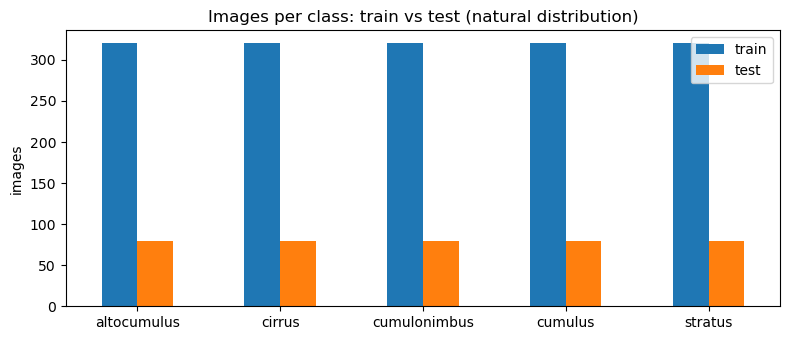

Test images that are identical to a training image: 10


In [24]:
# Class counts, train vs test
counts = pd.DataFrame({
    'train': np.bincount(y_train_raw, minlength=n_classes),
    'test':  np.bincount(y_test_raw,  minlength=n_classes),
}, index=class_names)
display(counts)

counts.plot(kind='bar', figsize=(8, 3.5), rot=0)
plt.title('Images per class: train vs test (natural distribution)')
plt.ylabel('images'); plt.tight_layout(); plt.show()

# Leak check: is any test image pixel-for-pixel identical to a training image?
def array_hash(a):
    return hashlib.md5(a.tobytes()).hexdigest()

train_hashes = {array_hash(a) for a in x_train_raw}
leaks = sum(array_hash(a) in train_hashes for a in x_test_raw)
print(f'Test images that are identical to a training image: {leaks}')

**In simple terms: what the data checks show**
- The first printout confirms the arrays are what Notebook 2 promised: pictures stored as whole numbers from 0 to 255, each 224 x 224 with 3 color channels. If an `assert` line fails, the array is not in that format, and the message says which part.
- The table and chart show how many images each cloud type has in train and in test. If one class is much smaller, section 3 will fix that in the **training set only**.
- The last line should say **0**. Anything above 0 means the same picture is in both sets, which would inflate the test score. If it is not 0, go back to Notebook 2's duplicate removal.
- This check only catches *exact* copies. Notebook 2's near-duplicate removal is what catches resized or re-saved copies.

## 3. The training-set pipeline: Balance, then Augment, then Embed

The three steps run in exactly this order, and **only on the training set**. The test set stays untouched at its natural class distribution, because that is what we are trying to measure.

### Why this order

| Step | Why it sits here |
|---|---|
| **1. Balance** | It works on a list of image positions, which is cheap, and it must come **before** augmentation. If we copied minority images *after* augmenting, the copies would be exact duplicates. Balancing first means each repeated image then gets its **own random transform**, so the extra examples are genuinely different. |
| **2. Augment** | It works on real pixel values (0-255). Brightness and contrast changes only make sense on real pixels, so augmentation must come **before** `preprocess_input`, which rescales the pixels. It also comes after balancing for the reason above. |
| **3. Embed** | It is last because the applications are frozen: the same image always gives the same embedding. We run each image through once, then reuse the result for as many probe runs as we like. Each application's own `preprocess_input` is the final step before the model. |

### Balancing choice: oversampling, not class weights
We oversample the minority classes in the training set (copying randomly chosen images until every class matches the largest). Class weights only re-weight the loss and add no new examples. Oversampling followed by augmentation gives the probe new, varied examples of the small classes. It also keeps the probe training code identical for every application. This follows the reasoning in U2-2_CNN-3_Imbalanced.

In [25]:
def oversample_indices(y, seed=SEED):
    # Positions of training images after topping every class up to the size of the largest one.
    rng = np.random.default_rng(seed)
    target = np.bincount(y, minlength=n_classes).max()
    parts = []
    for cls in range(n_classes):
        cls_idx = np.where(y == cls)[0]
        extra = target - len(cls_idx)
        if extra > 0:
            cls_idx = np.concatenate([cls_idx, rng.choice(cls_idx, size=extra, replace=True)])
        parts.append(cls_idx)
    idx = np.concatenate(parts)
    rng.shuffle(idx)
    return idx

balanced_idx = oversample_indices(y_train_raw)

before_after = pd.DataFrame({
    'before': np.bincount(y_train_raw, minlength=n_classes),
    'after':  np.bincount(y_train_raw[balanced_idx], minlength=n_classes),
}, index=class_names)
display(before_after)

,before,after
altocumulus,320,320
cirrus,320,320
cumulonimbus,320,320
cumulus,320,320
stratus,320,320


**In simple terms: balancing**
- `before` is how many training images each class has. `after` is how many it has once smaller classes are topped up by repeating randomly chosen images.
- If all five numbers in `before` are already equal, nothing changes. That is fine.
- The **test set is not touched**.

### 3.2 Augmentation: what we chose and why for clouds

| Transform | Setting | Why it suits cloud photos |
|---|---|---|
| Horizontal flip | on | A cloud has no handedness and there is no text in the photo, so a mirrored sky is still a believable sky. |
| Vertical flip | **off** | Sky is above and ground is below. A flipped photo puts clouds under the horizon, which no real photo does. |
| Rotation | about **±14°** (small) | People hold cameras slightly tilted, so small tilts are realistic. Heavy rotation would be wrong for sky photos with a horizon. |
| Zoom | **±15%** | Photos differ in how much sky fills the frame. This also helps the model not rely on one framing. |
| Brightness | **±15%** (mild) | Lighting varies across photos. We keep it mild because **darkness is a real clue** for storm clouds, so strong changes could blur cumulonimbus vs stratus. |
| Contrast | **±15%** (mild) | Haze and exposure change contrast. Kept mild for the same reason. |
| Color shifts | **off** | Sunsets and storm light are part of what separates cloud types, so we do not alter hue. |

In [26]:
augment = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.04, fill_mode='reflect'),   # 0.04 of a full turn, about 14 degrees
    layers.RandomZoom(0.15, fill_mode='reflect'),
    layers.RandomBrightness(0.15),                      # works on raw 0-255 pixels
    layers.RandomContrast(0.15),
], name='cloud_augment')

def augment_array(x_uint8, copies):
    # Return `copies` randomly augmented versions of every image (uint8, still 0-255).
    out = []
    for _ in range(copies):
        for s in range(0, len(x_uint8), 64):
            b = tf.cast(x_uint8[s:s + 64], tf.float32)
            a = augment(b, training=True).numpy()
            out.append(np.clip(a, 0, 255).astype('uint8'))
    return np.concatenate(out)

t0 = time.time()
x_train_base = x_train_raw[balanced_idx]      # balanced order (repeats allowed)
y_train_base = y_train_raw[balanced_idx]

print('Augmenting ...')
x_train_img = augment_array(x_train_base, AUG_COPIES)
y_train     = np.tile(y_train_base, AUG_COPIES)

x_test_img = x_test_raw                       # test images are used exactly as Notebook 2 saved them
y_test     = y_test_raw

print(f'train: {x_train_img.shape} | test: {x_test_img.shape} | prep time {time.time() - t0:.0f}s')

Augmenting ...
train: (3200, 224, 224, 3) | test: (400, 224, 224, 3) | prep time 8s


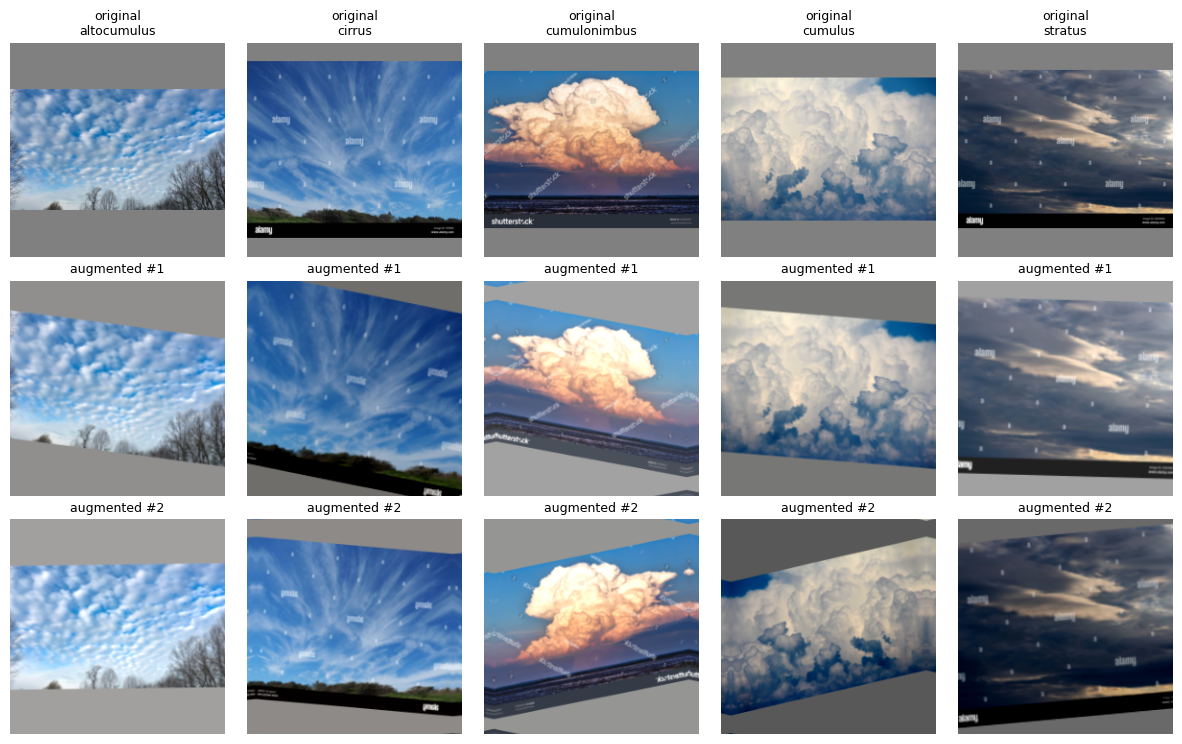

In [27]:
# Visual check: originals (top row) and their augmented versions (rows below)
fig, axes = plt.subplots(1 + 2, 5, figsize=(12, 7.5))
rng = np.random.default_rng(0)
picks = [rng.choice(np.where(y_train_base == c)[0]) for c in range(n_classes)]
for col, k in enumerate(picks):
    axes[0, col].imshow(x_train_base[k]);  axes[0, col].set_title(f'original\n{class_names[y_train_base[k]]}', fontsize=9)
    for row in (1, 2):
        axes[row, col].imshow(x_train_img[k + (row - 1) * len(y_train_base)])
        axes[row, col].set_title(f'augmented #{row}', fontsize=9)
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout(); plt.show()

**In simple terms: augmentation**
- We take each training image, repeat the minority-class ones, then make **2 randomly changed versions** of every image (a little flipped, tilted, zoomed, brighter or darker).
- The picture grid shows one image per class: the original on top, two changed versions below. Check that they still look like believable cloud photos. If the clouds are cut off or the sky looks wrong, the settings are too strong.
- The test images are **not** changed.
- All applications share these exact same augmented images, so differences between them cannot come from different augmentation.

### 3.3 Embedding

Each application is loaded with `include_top=False, pooling='avg'`, which removes its original 1000-class ImageNet head and ends with **one embedding vector per image**. Its own `preprocess_input` is applied to each batch just before the model sees it. The model is called in inference mode, so nothing in it can change.

Embeddings for both sets are cached in `CACHE_DIR`, along with how long they took, so restarting the kernel does not cost us the work.

In [28]:
def embed_both(key):
    """Embed the training and test images with one application. Returns embeddings, seconds, params."""
    cache = CACHE_DIR / f'P2_N3_{key}_{IMG_SIZE}_aug{AUG_COPIES}_n{len(y_train)}_{len(y_test)}.npz'
    if cache.exists() and not FORCE_RECOMPUTE:
        z = np.load(cache)
        print(f'  loaded cached embeddings from {cache.name}')
        return z['x_train'], z['x_test'], float(z['seconds']), int(z['params'])

    app = APPS[key]
    keras.backend.clear_session()
    model = app['builder'](weights='imagenet', include_top=False, pooling='avg',
                           input_shape=(IMG_SIZE, IMG_SIZE, 3))
    model.trainable = False

    def run(x_uint8):
        out = []
        for s in range(0, len(x_uint8), EMBED_BATCH):
            b = app['preprocess'](x_uint8[s:s + EMBED_BATCH].astype('float32'))   # THIS app's own scaling
            out.append(model(b, training=False).numpy())
        return np.concatenate(out)

    t0 = time.time()
    x_train, x_test = run(x_train_img), run(x_test_img)
    seconds = time.time() - t0
    params = model.count_params()
    np.savez(cache, x_train=x_train, x_test=x_test, seconds=seconds, params=params)
    return x_train, x_test, seconds, params

**In simple terms: embedding**
- `embed_both` runs every image through one application and keeps the list of numbers it produces (the embedding).
- `model.trainable = False` and `training=False` are two locks that keep the application's pretrained knowledge from changing.
- The time it takes is saved, because our summary table asks for embedding time.

## 4. The linear probe and the evaluation helpers

The probe is a `Sequential` model with a **single `Dense` layer**: one unit per class, softmax activation, taking the embedding vector as input. Every probe uses the **same architecture and the same training settings**. Only the input size changes, to match each application's embedding length.

In [29]:
def build_probe(embedding_dim, n_classes):
    probe = keras.Sequential([
        layers.Input(shape=(embedding_dim,)),
        layers.Dense(n_classes, activation='softmax'),
    ], name='linear_probe')
    probe.compile(optimizer=keras.optimizers.Adam(learning_rate=PROBE['learning_rate']),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return probe


def evaluate(name, y_true, y_pred):
    """Accuracy, macro-F1, full report, per-class recall, confusion matrix with class names."""
    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average='macro')
    print(f'{name}: accuracy = {acc:.3f} | macro-F1 = {macro_f1:.3f}\n')
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

    recall = pd.Series(recall_score(y_true, y_pred, labels=range(n_classes), average=None),
                       index=class_names, name='recall')
    cm = confusion_matrix(y_true, y_pred, labels=range(n_classes))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1.2, 1]})
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names,
                yticklabels=class_names, ax=axes[0], cbar=False)
    axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True'); axes[0].set_title(f'{name}: confusion matrix')
    recall.sort_values().plot(kind='barh', ax=axes[1], color='tab:blue')
    axes[1].set_xlim(0, 1); axes[1].set_xlabel('recall'); axes[1].set_title('Per-class recall')
    plt.tight_layout(); plt.show()

    if acc >= 0.98:
        print('WARNING: accuracy this close to 100% on a small scraped dataset is suspicious. '
              'Check for the same image in train and test, or classes separated by background.')
    return acc, macro_f1, recall, cm


RESULTS = {}   # key -> everything the summary needs

def run_app(key):
    app = APPS[key]
    print(f"=== {app['name']} ({app['size']}) ===")
    x_train, x_test, embed_seconds, app_params = embed_both(key)
    print(f'  embedding length: {x_train.shape[1]} | embedding time: {embed_seconds:.0f}s | '
          f'app parameters (no top): {app_params / 1e6:.1f} M')

    keras.backend.clear_session()
    tf.random.set_seed(SEED)
    probe = build_probe(x_train.shape[1], n_classes)
    t0 = time.time()
    history = probe.fit(x_train, y_train, epochs=PROBE['epochs'],
                        batch_size=PROBE['batch_size'], shuffle=True, verbose=0)
    probe_seconds = time.time() - t0
    print(f"  probe: {probe.count_params()} parameters | trained in {probe_seconds:.1f}s | "
          f"final training accuracy {history.history['accuracy'][-1]:.3f}")

    y_pred = probe.predict(x_test, verbose=0).argmax(axis=1)
    acc, macro_f1, recall, cm = evaluate(app['name'], y_test, y_pred)

    probe.save(MODEL_DIR / f'P2_N3_{key}.keras')
    print(f"  saved {MODEL_DIR / f'P2_N3_{key}.keras'}")

    RESULTS[key] = dict(name=app['name'], app_params=app_params, embed_seconds=embed_seconds,
                        probe_params=probe.count_params(), probe_seconds=probe_seconds,
                        accuracy=acc, macro_f1=macro_f1, recall=recall, cm=cm)

**In simple terms: the probe and the report**
- `build_probe` makes the one-layer model. Its size is just `embedding length x 5 classes + 5`, so it is tiny.
- `evaluate` prints accuracy, macro-F1 (the average of each class's F1, which treats all five classes equally), the full report, and draws two pictures: the **confusion matrix** (rows are the true cloud, columns are what the model said) and **per-class recall** (of all the real cumulus photos, how many did we find?).
- Per-class recall matters because an overall average can hide a class the model has given up on.
- `run_app` does everything for one application: embed, train the probe, evaluate, and save the probe as `models/P2_N3_<application>.keras`.

## 5.1 MobileNetV2 (small)

Scaling: its own `preprocess_input` rescales pixels to **[-1, 1]**. Saved probe: `models/P2_N3_mobilenetv2.keras`.

=== MobileNetV2 (small) ===
  loaded cached embeddings from P2_N3_mobilenetv2_224_aug2_n3200_400.npz
  embedding length: 1280 | embedding time: 52s | app parameters (no top): 2.3 M
  probe: 6405 parameters | trained in 4.4s | final training accuracy 0.981
MobileNetV2: accuracy = 0.772 | macro-F1 = 0.772

              precision    recall  f1-score   support

 altocumulus      0.818     0.900     0.857        80
      cirrus      0.925     0.775     0.844        80
cumulonimbus      0.735     0.762     0.748        80
     cumulus      0.688     0.800     0.740        80
     stratus      0.725     0.625     0.671        80

    accuracy                          0.772       400
   macro avg      0.778     0.772     0.772       400
weighted avg      0.778     0.772     0.772       400



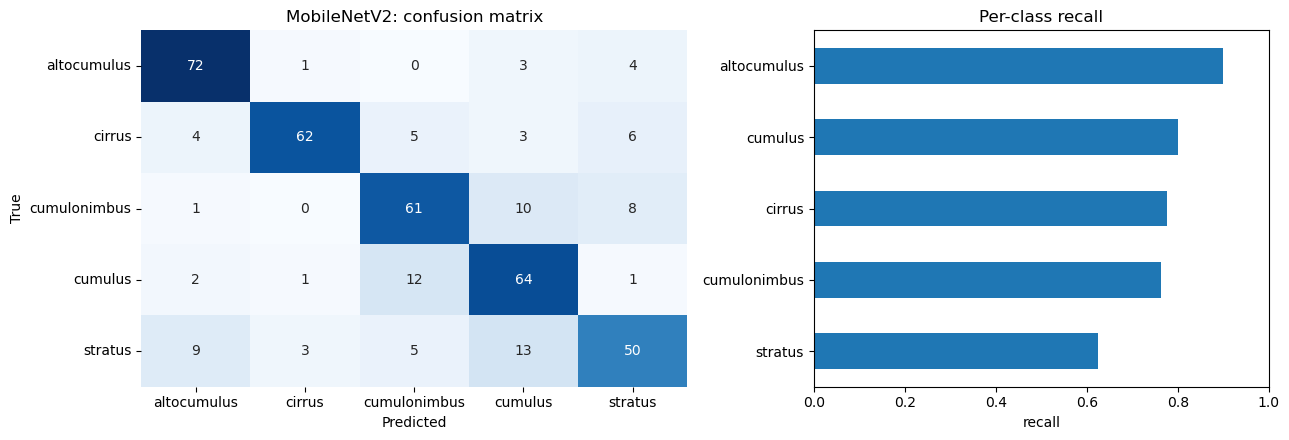

  saved models\P2_N3_mobilenetv2.keras


In [30]:
run_app('mobilenetv2')

**In simple terms: MobileNetV2 results**
- The first lines show the embedding length, how long embedding took, and how big the probe is.
- Then come the scores and the two pictures. Look at which rows of the confusion matrix have the most numbers off the diagonal, and which bar in the recall chart is shortest.

## 5.2 EfficientNetV2S (medium)

Scaling: rescaling is baked into the model, so it takes **raw 0-255** pixels (`preprocess_input` passes them through). Saved probe: `models/P2_N3_effnetv2s.keras`.

=== EfficientNetV2S (medium) ===
  loaded cached embeddings from P2_N3_effnetv2s_224_aug2_n3200_400.npz
  embedding length: 1280 | embedding time: 185s | app parameters (no top): 20.3 M
  probe: 6405 parameters | trained in 4.2s | final training accuracy 0.916
EfficientNetV2S: accuracy = 0.767 | macro-F1 = 0.766

              precision    recall  f1-score   support

 altocumulus      0.851     0.787     0.818        80
      cirrus      0.818     0.900     0.857        80
cumulonimbus      0.762     0.762     0.762        80
     cumulus      0.716     0.787     0.750        80
     stratus      0.686     0.600     0.640        80

    accuracy                          0.767       400
   macro avg      0.767     0.768     0.766       400
weighted avg      0.767     0.767     0.766       400



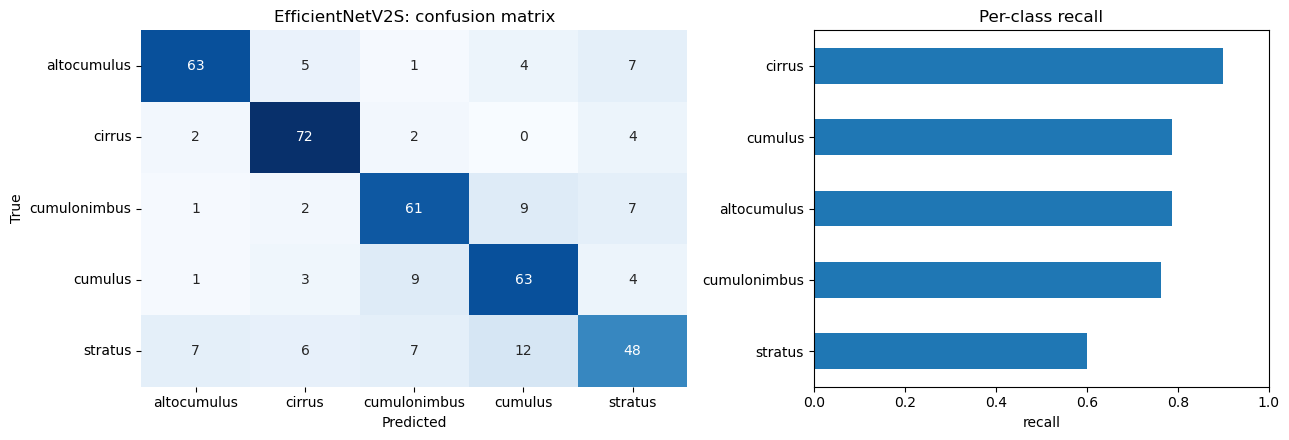

  saved models\P2_N3_effnetv2s.keras


In [31]:
run_app('effnetv2s')

**In simple terms: EfficientNetV2S results**
- The first lines show the embedding length, how long embedding took, and how big the probe is.
- Then come the scores and the two pictures. Look at which rows of the confusion matrix have the most numbers off the diagonal, and which bar in the recall chart is shortest.

## 5.3 ResNet50 (medium)

Scaling: its own `preprocess_input` flips RGB to BGR and subtracts the ImageNet channel means. Saved probe: `models/P2_N3_resnet50.keras`.

=== ResNet50 (medium) ===
  loaded cached embeddings from P2_N3_resnet50_224_aug2_n3200_400.npz
  embedding length: 2048 | embedding time: 136s | app parameters (no top): 23.6 M
  probe: 10245 parameters | trained in 4.4s | final training accuracy 0.984
ResNet50: accuracy = 0.810 | macro-F1 = 0.811

              precision    recall  f1-score   support

 altocumulus      0.838     0.838     0.838        80
      cirrus      0.910     0.887     0.899        80
cumulonimbus      0.833     0.812     0.823        80
     cumulus      0.756     0.775     0.765        80
     stratus      0.720     0.738     0.728        80

    accuracy                          0.810       400
   macro avg      0.811     0.810     0.811       400
weighted avg      0.811     0.810     0.811       400



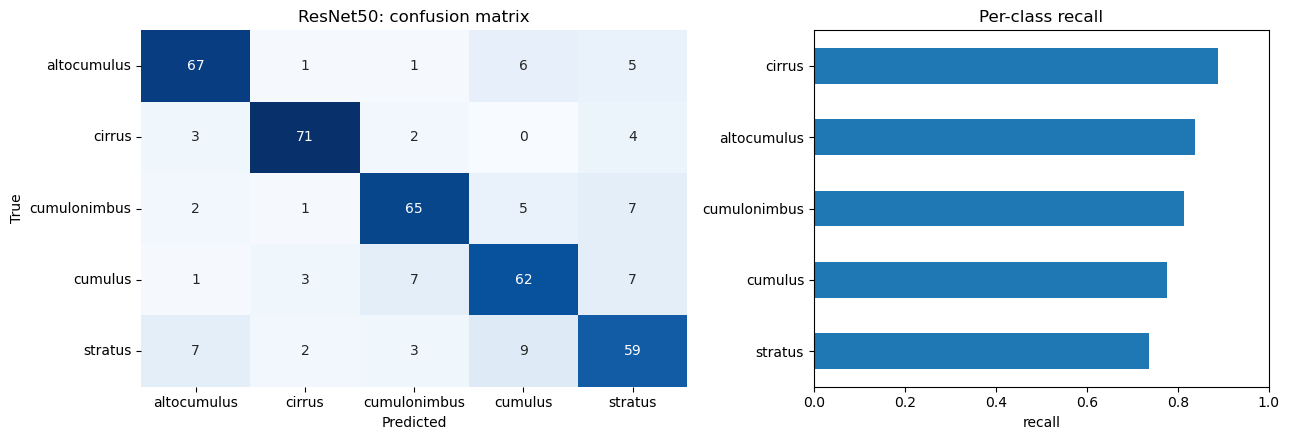

  saved models\P2_N3_resnet50.keras


In [32]:
run_app('resnet50')

**In simple terms: ResNet50 results**
- The first lines show the embedding length, how long embedding took, and how big the probe is.
- Then come the scores and the two pictures. Look at which rows of the confusion matrix have the most numbers off the diagonal, and which bar in the recall chart is shortest.

## 5.4 EfficientNetV2M (large)

Scaling: rescaling is baked into the model, so it takes **raw 0-255** pixels (`preprocess_input` passes them through). Saved probe: `models/P2_N3_effnetv2m.keras`.

=== EfficientNetV2M (large) ===
  loaded cached embeddings from P2_N3_effnetv2m_224_aug2_n3200_400.npz
  embedding length: 1280 | embedding time: 308s | app parameters (no top): 53.2 M
  probe: 6405 parameters | trained in 4.6s | final training accuracy 0.874
EfficientNetV2M: accuracy = 0.730 | macro-F1 = 0.728

              precision    recall  f1-score   support

 altocumulus      0.789     0.750     0.769        80
      cirrus      0.884     0.762     0.819        80
cumulonimbus      0.680     0.825     0.746        80
     cumulus      0.703     0.800     0.749        80
     stratus      0.612     0.512     0.558        80

    accuracy                          0.730       400
   macro avg      0.734     0.730     0.728       400
weighted avg      0.734     0.730     0.728       400



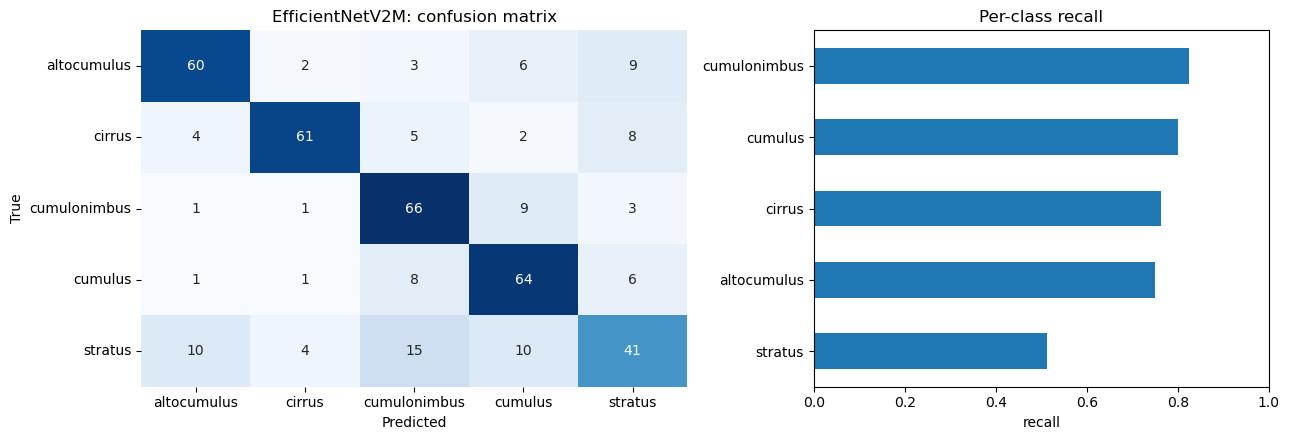

  saved models\P2_N3_effnetv2m.keras


In [33]:
run_app('effnetv2m')

**In simple terms: EfficientNetV2M results**
- The first lines show the embedding length, how long embedding took, and how big the probe is.
- Then come the scores and the two pictures. Look at which rows of the confusion matrix have the most numbers off the diagonal, and which bar in the recall chart is shortest.

## 6. Comparison

One table, one plot, and a few numbers computed from the results so our discussion rests on facts rather than impressions.

,Keras application,App params (M),Embedding time (s),Probe params,Probe train time (s),Test accuracy,Macro-F1
0,MobileNetV2,2.3,52,6405,4.4,0.772,0.772
1,EfficientNetV2S,20.3,185,6405,4.2,0.767,0.766
2,ResNet50,23.6,136,10245,4.4,0.810,0.811
3,EfficientNetV2M,53.2,308,6405,4.6,0.730,0.728


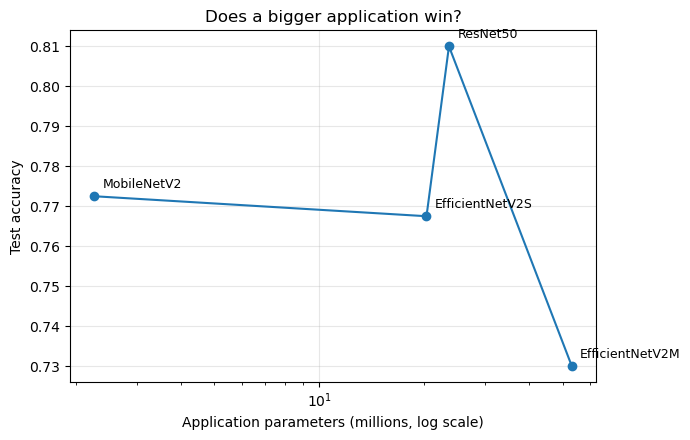

In [34]:
summary = pd.DataFrame([{
    'Keras application': r['name'],
    'App params (M)': r['app_params'] / 1e6,
    'Embedding time (s)': r['embed_seconds'],
    'Probe params': r['probe_params'],
    'Probe train time (s)': r['probe_seconds'],
    'Test accuracy': r['accuracy'],
    'Macro-F1': r['macro_f1'],
} for r in RESULTS.values()]).sort_values('App params (M)').reset_index(drop=True)

display(summary.style.format({'App params (M)': '{:.1f}', 'Embedding time (s)': '{:.0f}',
                              'Probe train time (s)': '{:.1f}', 'Test accuracy': '{:.3f}',
                              'Macro-F1': '{:.3f}'}))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(summary['App params (M)'], summary['Test accuracy'], marker='o', color='tab:blue')
for _, row in summary.iterrows():
    ax.annotate(row['Keras application'], (row['App params (M)'], row['Test accuracy']),
                textcoords='offset points', xytext=(6, 6), fontsize=9)
ax.set_xscale('log')
ax.set_xlabel('Application parameters (millions, log scale)')
ax.set_ylabel('Test accuracy')
ax.set_title('Does a bigger application win?')
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [35]:
# Facts for the discussion, computed from the results above
small, large = summary.iloc[0], summary.iloc[-1]
best = summary.loc[summary['Test accuracy'].idxmax()]
print(f"Best accuracy: {best['Keras application']} at {best['Test accuracy']:.3f}")
print(f"Smallest -> largest: accuracy changes by {(large['Test accuracy'] - small['Test accuracy']) * 100:+.1f} points, "
      f"parameters grow {large['App params (M)'] / small['App params (M)']:.0f}x, "
      f"embedding time grows {large['Embedding time (s)'] / small['Embedding time (s)']:.1f}x")

# Step-by-step gains, ordered by size
for a, b in zip(summary.index[:-1], summary.index[1:]):
    d = (summary.loc[b, 'Test accuracy'] - summary.loc[a, 'Test accuracy']) * 100
    print(f"  {summary.loc[a, 'Keras application']:<16} -> {summary.loc[b, 'Keras application']:<16} {d:+.1f} accuracy points")

# Most-confused pair per application (off-diagonal cells, both directions added together)
print('\nMost-confused pair per application:')
pair_votes = {}
for r in RESULTS.values():
    cm = r['cm']
    best_pair, best_n = None, -1
    for i in range(n_classes):
        for j in range(i + 1, n_classes):
            n = cm[i, j] + cm[j, i]
            if n > best_n:
                best_pair, best_n = (class_names[i], class_names[j]), n
    pair_votes[r['name']] = best_pair
    print(f"  {r['name']:<16} {best_pair[0]} <-> {best_pair[1]}  ({best_n} mistakes)")

predicted = {'cumulus', 'altocumulus'}
hits = [n for n, p in pair_votes.items() if set(p) == predicted]
print(f"\nNotebook 1 predicted cumulus <-> altocumulus. Matched by: {hits if hits else 'none of the applications'}")

Best accuracy: ResNet50 at 0.810
Smallest -> largest: accuracy changes by -4.2 points, parameters grow 24x, embedding time grows 5.9x
  MobileNetV2      -> EfficientNetV2S  -0.5 accuracy points
  EfficientNetV2S  -> ResNet50         +4.3 accuracy points
  ResNet50         -> EfficientNetV2M  -8.0 accuracy points

Most-confused pair per application:
  MobileNetV2      cumulonimbus <-> cumulus  (22 mistakes)
  EfficientNetV2S  cumulonimbus <-> cumulus  (18 mistakes)
  ResNet50         cumulus <-> stratus  (16 mistakes)
  EfficientNetV2M  altocumulus <-> stratus  (19 mistakes)

Notebook 1 predicted cumulus <-> altocumulus. Matched by: none of the applications


**In simple terms: the comparison**
- The table puts all applications side by side. The plot has parameters (model size) across the bottom and accuracy up the side. A line that **rises steeply and then flattens** means extra size stops paying off.
- The last cell does the counting for us: which application won, how much accuracy the biggest one gained for how much extra time, and which pair of clouds each model mixed up most.

## 7. Discussion

*TeamKAI: write these answers after the cells above have run, using the numbers printed above. Each prompt says what to look at.*

**Does bigger win?**  
Look at the table and the plot. Say whether accuracy rises with parameter count, and whether the ranking is exactly by size. Compare EfficientNetV2S and ResNet50 (similar size, different design): if they differ a lot, design matters as much as size.

**Where do the returns flatten?**  
Use the step-by-step gains printed above. Name the step where the gain becomes small (for example, less than one point), and say whether that gain is bigger than what we would expect from noise. Remember the test set is small, so one extra correct image moves accuracy by a fraction of a point. A difference of one or two images is not evidence.

**Was the largest application worth its extra embedding time on a dataset this size?**  
Compare the accuracy gain with the time multiple printed above. State your verdict and the number it rests on.

**Revisiting our Notebook 1 prediction**  
We predicted the most-confused pair would be `cumulus` and `altocumulus`. Use the printed result: say whether the confusion matrices agree, which pair they show instead if not, and offer one reason using what we saw in the pictures (for example, storm skies that look like stratus, or fog photos in the stratus class).

**What would make us doubt these results?**  
If any application scored close to 100%, treat it as a warning, not a win. The most common causes are the same image in both train and test, or classes that differ by background rather than by the cloud. Notebook 4 checks what the model is really looking at.

## 8. Export

Each trained probe was already saved as `models/P2_N3_<application>.keras` by `run_app`. The application name in the filename is how Notebook 4 and the app know which Keras application to rebuild and join to each probe. We now save the label-to-index mapping next to them and list everything in the folder.

In [36]:
with open(MODEL_DIR / 'P2_label_map.json', 'w') as f:
    json.dump(label_to_index, f, indent=2)

for p in sorted(MODEL_DIR.glob('P2_*')):
    print(f'{p}  ({p.stat().st_size / 1024:.1f} KB)')

models\P2_label_map.json  (0.1 KB)
models\P2_N3_effnetv2m.keras  (90.7 KB)
models\P2_N3_effnetv2s.keras  (90.7 KB)
models\P2_N3_mobilenetv2.keras  (90.7 KB)
models\P2_N3_resnet50.keras  (135.7 KB)


**In simple terms: export**
- You should see one `.keras` file per application plus `P2_label_map.json`. Each probe file is only a few kilobytes because the probe is just one small layer.
- **What is not saved:** the pretrained applications themselves. Notebook 4 and the app re-download them from Keras and join each one to its probe.
- The images and cached embeddings stay outside the repo, as with Notebook 1.